# Active inference with `pymdp` (JAX)

Authors: Aswin Paul, Ifrah Saeed. Prepared for the NeurIPS 2026 education track.

How should an agent act when it does not yet know where its goal lies? It must reach the outcomes it prefers, and it must also resolve the uncertainty that stands between itself and those outcomes. Reinforcement learning addresses the first demand directly, and typically values information only through the reward it eventually leads to, unless an exploration bonus is added. Active inference scores both demands within a single objective, the expected free energy (EFE), so that resolving uncertainty has value in its own right and information seeking follows from the agent's generative model.

In this notebook, we build a small generative model for a 'cue chaining' task, run the perception, planning and action loop on it, and inspect the agent's beliefs at every timestep. The task is chosen so that the reward cannot be located without first visiting two cues that carry no reward themselves. The notebook is written for readers with no prior exposure to active inference. We assume familiarity with Python and NumPy, and with basic probability, i.e., conditional distributions and Bayes' rule.

In what follows, we first set up the environment (Sec. 1) and describe the task (Sec. 2). We then specify the generative model (Sec. 3) and the agent's preferences, prior and planning horizon (Sec. 4). Sections 5 to 7 run the same loop at three levels of the `pymdp` API, from individual calls to a compiled episode, and Sec. 8 examines what the agent believed along the way. Section 9 examines the planning horizon, the scale of the preferences, the contribution of the epistemic term and the cost of preference shaping, Sec. 10 removes part of the model and lets the agent learn it, Sec. 11 animates the episode, and Sec. 12 summarises what was shown. The task and the agent configuration in Secs. 2 to 4 follow the official `pymdp` cue chaining demo (`examples/envs/cue_chaining_demo.ipynb`), which runs the agent and plots its trajectory, and Secs. 5 to 10 build on that starting point. The full notebook runs on a laptop CPU in around 40 seconds.

## 1. Setup

We work in an isolated environment and let the resolver choose compatible versions, so that the results below can be reproduced on another machine.

```bash
uv init neurips-active-inference
cd neurips-active-inference
uv add inferactively-pymdp jupyterlab
cp /path/to/demo-generative-model.ipynb .
uv run jupyter lab
```

`uv` writes a `.venv/` and a lockfile, which together record the versions used here. Note that `jax` should not be pinned by hand, since `pymdp` already constrains it to `jax<0.11.1` and an explicit pin tends to conflict with that constraint. The CPU build of JAX is sufficient throughout.

In [3]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

import jax.numpy as jnp
import jax.random as jr
import jax.tree_util as jtu
from jax import vmap

from pymdp.agent import Agent
from pymdp.envs.cue_chaining import CueChainingEnv
from pymdp.envs.rollout import infer_and_plan, rollout

ModuleNotFoundError: No module named 'numpy'

## 2. The Task: Cue Chaining

A reward maximising agent values a location that pays nothing only through the reward it later leads to. The cue chaining task is built so that the reward cannot be found without such visits, and lies many steps beyond them.

A mouse occupies a 5x7 grid. The reward location is hidden, and the only route to it runs through two cues in sequence.

```
       c0     c1     c2     c3     c4     c5     c6
 r0  START    .      L1     .      .      .      .
 r1    .      .      .      L2     .      R1     .
 r2   CUE1    .      .      .      .      .      .
 r3    .      .      .      L3     .      R2     .
 r4    .      .      L4     .      .      .      .
```

Standing on CUE1 reveals which of the four locations L1 to L4 holds the 'active' cue on this trial. Standing on the active cue then reveals whether the reward sits at R1 or R2. One of R1 and R2 holds cheese and the other a shock, so an agent that guesses is correct half of the time.

Neither cue is rewarding in itself. A reward maximising agent can still value the cues, but only by planning or learning far enough ahead to see the reward they lead to, which here lies around ten steps from the start. Under active inference, visiting a cue has value because it is expected to resolve uncertainty about the hidden states, even when the reward lies beyond the planning horizon. Importantly, no rule in the code below tells the agent to visit the cues, and this behaviour follows from the objective alone.

For the episodes below, we fix the active cue to L4 and the reward to R2. The agent is told neither. In the next section, we write down what the agent does know.

In [2]:
env = CueChainingEnv(
    grid_shape=(5, 7),
    start_location=(0, 0),
    cue1_location=(2, 0),
    cue2_locations=((0, 2), (1, 3), (3, 3), (4, 2)),
    reward_locations=((1, 5), (3, 5)),
    cue2_state=3,        # L4 is the active cue
    reward_condition=1,  # reward at R2
)

## 3. The Generative Model

The agent's knowledge of the task is held in three arrays.

- **A**, the likelihood $p(o \mid s)$, over four observation modalities: location, cue1, cue2 and reward.
- **B**, the transitions $p(s' \mid s, u)$, over three hidden state factors: location, cue2 state and reward condition.
- **D**, the prior over initial states.

Here, $o$ stands for an observation, $s$ for a hidden state, $s'$ for the next state and $u$ for an action. The state space is factorised into 35 locations, 4 cue2 states and 2 reward conditions, instead of a single table of 280 joint states. The lists `A_dependencies` and `B_dependencies` declare which factors each modality and each factor depend on, and this sparsity keeps inference tractable.

The same lists determine the array shapes. Each `A[m]` has a leading axis for its own observations, followed by one axis per factor in `A_dependencies[m]`, so `A[2]` is indexed as (cue2 observation, location, cue2 state, reward condition). Each `B[f]` is indexed as (next state, current state, action), and a factor with a single action is one the agent cannot control. The first cell below prints these axes.

Note what the dependencies leave out. `A[3]` depends on location and reward condition but not on the cue2 state, so the reward observed at a square depends only on where the reward is. `B_dependencies` couples no factor to any other, so moving around cannot change where the reward is, and both latent factors stay fixed for the length of an episode.

The second cell displays slices of `A[1]` and `A[2]`. On the square that carries information, each slice is an identity matrix over the factor being revealed, while everywhere else all probability mass sits on the `Null` observation. This contrast is what makes the cues informative, and `A[3]` follows the same pattern at the reward squares.

For simplicity, we hand the agent `env.A` and `env.B` directly, so its generative model matches the environment exactly. Section 10 relaxes this assumption.

In [3]:
factor_names = ("location", "cue2 state", "reward condition")
modality_names = ("location", "cue1", "cue2", "reward")

print("A[m] is (observation, *A_dependencies[m]): one axis per factor the modality reads")
for m, (a, dep) in enumerate(zip(env.A, env.A_dependencies)):
    axes = " x ".join((f"{modality_names[m]} obs",) + tuple(factor_names[f] for f in dep))
    print(f"  A[{m}]  {str(a.shape):<14} deps {str(dep):<10} {axes}")

print("\nB[f] is (next state, current state, action)")
for f, (b, dep) in enumerate(zip(env.B, env.B_dependencies)):
    control = "controllable" if b.shape[-1] > 1 else "uncontrollable"
    print(f"  B[{f}]  {str(b.shape):<14} deps {str(dep):<10} "
          f"next {factor_names[f]} x {factor_names[f]} x {b.shape[-1]} action(s), {control}")

print("\nD[f] is (state,)")
for f, d in enumerate(env.D):
    print(f"  D[{f}]  {str(d.shape):<14} {'':<15} {factor_names[f]}")

A[m] is (observation, *A_dependencies[m]): one axis per factor the modality reads
  A[0]  (35, 35)       deps [0]        location obs x location
  A[1]  (5, 35, 4)     deps [0, 1]     cue1 obs x location x cue2 state
  A[2]  (3, 35, 4, 2)  deps [0, 1, 2]  cue2 obs x location x cue2 state x reward condition
  A[3]  (3, 35, 2)     deps [0, 2]     reward obs x location x reward condition

B[f] is (next state, current state, action)
  B[0]  (35, 35, 5)    deps [0]        next location x location x 5 action(s), controllable
  B[1]  (4, 4, 1)      deps [1]        next cue2 state x cue2 state x 1 action(s), uncontrollable
  B[2]  (2, 2, 1)      deps [2]        next reward condition x reward condition x 1 action(s), uncontrollable

D[f] is (state,)
  D[0]  (35,)                          location
  D[1]  (4,)                           cue2 state
  D[2]  (2,)                           reward condition


In [4]:
i_start = env.coords_to_index(env.start_location)
i_cue1 = env.coords_to_index(env.cue1_location)
i_L4 = env.coords_to_index(env.cue2_locations[3])


def show(block, rows, cols, caption):
    print(caption)
    display(pd.DataFrame(np.asarray(block).T, index=list(rows), columns=list(cols)))


show(env.A[1][:, i_cue1, :], env.cue2_names, env.cue1_obs_names,
     "A[1] on CUE1: the observation is the live cue")
show(env.A[1][:, i_start, :], env.cue2_names, env.cue1_obs_names,
     "A[1] on START: all mass on Null")

show(env.A[2][:, i_L4, 3, :], env.reward_condition_names, env.cue2_obs_names,
     "A[2] on L4 while L4 is live: reveals the reward condition")
show(env.A[2][:, i_L4, 0, :], env.reward_condition_names, env.cue2_obs_names,
     "A[2] on L4 while L1 is live: silent")

A[1] on CUE1: the observation is the live cue


,Null,L1,L2,L3,L4
L1,0.0,1.0,0.0,0.0,0.0
L2,0.0,0.0,1.0,0.0,0.0
L3,0.0,0.0,0.0,1.0,0.0
L4,0.0,0.0,0.0,0.0,1.0


A[1] on START: all mass on Null


,Null,L1,L2,L3,L4
L1,1.0,0.0,0.0,0.0,0.0
L2,1.0,0.0,0.0,0.0,0.0
L3,1.0,0.0,0.0,0.0,0.0
L4,1.0,0.0,0.0,0.0,0.0


A[2] on L4 while L4 is live: reveals the reward condition


,Null,reward_on_top,reward_on_bottom
TOP,0.0,1.0,0.0
BOTTOM,0.0,0.0,1.0


A[2] on L4 while L1 is live: silent


,Null,reward_on_top,reward_on_bottom
TOP,1.0,0.0,0.0
BOTTOM,1.0,0.0,0.0


## 4. The Agent: Preferences, Prior and Horizon

Three further objects complete the agent.

- **C**, the prior preferences, given as log-preferences over observations. Positive values mark outcomes the agent seeks and negative values outcomes it avoids.
- **D**, the agent's prior over initial states. It places all mass on the true starting location and is uniform over both latent factors, so the agent knows where it is but not which cue is active or where the reward is.
- **`policy_len`**, the planning horizon, i.e., the number of future steps over which each policy is evaluated.

Each policy $\pi$ is scored by its negative expected free energy, summed over the `policy_len` steps of the policy,

$$
-G(\pi) = \sum_{\tau} \Big( \underbrace{\mathbb{E}_{q(o_\tau \mid \pi)}\big[C(o_\tau)\big]}_{\text{pragmatic value}} + \underbrace{\mathbb{E}_{q(o_\tau \mid \pi)}\Big[D_{KL}\big[q(s_\tau \mid o_\tau, \pi) \,\|\, q(s_\tau \mid \pi)\big]\Big]}_{\text{epistemic value}} \Big).
$$

Here, $q(o_\tau \mid \pi)$ stands for the observations the agent expects at future step $\tau$ under policy $\pi$, and $q(s_\tau \mid \pi)$ for the corresponding beliefs about hidden states. The pragmatic value rewards policies expected to produce preferred observations. The epistemic value rewards policies whose observations are expected to change the agent's beliefs, i.e., to resolve uncertainty. This is what `neg_efe` holds, and the agent favours policies with higher values.

The same quantity can be written in a second form that clarifies the role of `C`. Normalising the preferences gives a target distribution over observations, $\tilde{p}(o) \propto \exp C(o)$, and

$$
G(\pi) = \sum_{\tau} \Big( \underbrace{D_{KL}\big[q(o_\tau \mid \pi) \,\|\, \tilde{p}(o_\tau)\big]}_{\text{risk}} + \underbrace{\mathbb{E}_{q(s_\tau \mid \pi)}\big[H[p(o_\tau \mid s_\tau)]\big]}_{\text{ambiguity}} \Big) + \text{const}.
$$

Here, risk measures how far the observations expected under $\pi$ lie from the preferred distribution, and ambiguity measures how uncertain observations remain given the states the policy is expected to visit. Under this reading, `C` specifies the outcomes the agent expects to observe, and policies are favoured when their predicted outcomes match that distribution. Multiplying `C` by a factor sharpens or flattens $\tilde{p}(o)$, i.e., it changes the precision of the agent's preferences, which is the effect examined in Sec. 9.

It is also helpful to state where active inference departs from a partially observable Markov decision process (POMDP). The arrays `A`, `B` and `D` define a POMDP, and the state inference in Sec. 5 is approximate Bayesian belief updating of the kind any POMDP agent performs. The two frameworks differ in how actions are chosen. A POMDP agent maximises expected cumulative reward, and an optimal solution over belief states already seeks information, since the value of information is contained in the Bellman equation. An active inference agent scores policies by the expected free energy above, in which information gain appears as an explicit term. In `pymdp`, policies are fixed action sequences evaluated before their observations arrive, so this explicit term is what gives the cues value at a modest horizon, and Sec. 9 tests this directly.

The horizon matters in this task because each policy is scored only over `policy_len` steps. If no informative or preferred observation lies within that depth, all policies score alike and the agent has no reason to move. From L4 the reward lies four steps away, so we set `policy_len=4`. With 5 actions, the agent then scores $5^4 = 625$ policies at every timestep.

The scale of `C` also matters, because only the pragmatic term depends on it. Adding a constant to `C` shifts every policy's score equally and leaves the ranking unchanged. However, multiplying `C` by a factor changes the weight of the pragmatic term against the epistemic term, and can therefore change which policy is chosen. Section 9 examines when this happens. In the next section, we run the agent one step at a time.

In [5]:
C = [jnp.zeros(a.shape[0]) for a in env.A]
C[3] = C[3].at[1].set(3.0)   # Cheese
C[3] = C[3].at[2].set(-6.0)  # Shock

D_agent = [
    env.D[0],                                     # true starting location
    jnp.ones_like(env.D[1]) / env.D[1].shape[0],  # uniform over cue2 state
    jnp.ones_like(env.D[2]) / env.D[2].shape[0],  # uniform over reward condition
]

agent = Agent(
    A=env.A,
    B=env.B,
    C=C,
    D=D_agent,
    A_dependencies=env.A_dependencies,
    B_dependencies=env.B_dependencies,
    policy_len=4,
    action_selection="deterministic",
    batch_size=1,
)

## 5. The Loop by Hand (Level 1)

Sections 5 to 7 run the same computation at three levels of the `pymdp` API. We begin at the lowest level, where every call is visible, and check at each higher level that the result is unchanged.

A single step of active inference consists of four calls.

1. `agent.infer_states(obs, empirical_prior)` returns `qs`, the posterior over hidden states.
2. `agent.infer_policies(qs)` returns `qpi`, the posterior over policies, and `neg_efe`, the negative expected free energy of each policy.
3. `agent.sample_action(qpi, rng_key)` selects an action.
4. `env.step(...)` returns the next observation.

At $t=0$ the empirical prior is `D`. At every later step, it is the previous posterior propagated through `B` under the action taken, which `agent.update_empirical_prior(action, qs)` computes. Since the agent has not yet visited either cue, we expect its beliefs about both latent factors to remain uniform after this first step.

In [6]:
key = jr.PRNGKey(0)
key, key_reset = jr.split(key)
obs, env_state = vmap(env.reset)(jr.split(key_reset, agent.batch_size))

qs = agent.infer_states(observations=obs, empirical_prior=agent.D)
qpi, neg_efe = agent.infer_policies(qs)

key, key_act = jr.split(key)
action = agent.sample_action(qpi, rng_key=jr.split(key_act, agent.batch_size))

key, key_step = jr.split(key)
obs_next, env_state_next = vmap(env.step)(jr.split(key_step, agent.batch_size), env_state, action)

prior_next = agent.update_empirical_prior(action, qs)

print("qs[1] cue2 state  ", qs[1].ravel())
print("qs[2] reward cond ", qs[2].ravel())
print("policies scored   ", qpi.shape[-1])
print("action            ", env.ACTION_LABELS[int(action[0, 0])])
print("location at t=0   ", env.index_to_coords(int(obs[0].ravel()[0])))
print("location at t=1   ", env.index_to_coords(int(obs_next[0].ravel()[0])))

qs[1] cue2 state   [0.25 0.25 0.25 0.25]
qs[2] reward cond  [0.5 0.5]
policies scored    625
action             DOWN
location at t=0    (0, 0)
location at t=1    (1, 0)


## 6. One Step with `infer_and_plan` (Level 2)

The function `infer_and_plan` performs the same four calls, together with two pieces of bookkeeping that are easy to get wrong by hand. First, it selects the empirical prior, using `D` when `action_prev is None` and the propagated posterior otherwise. Second, when learning is enabled, it updates the model parameters after planning and before action selection, so the action is drawn from the updated model.

The agent is returned by the call because `pymdp` agents are immutable JAX objects, and learning produces a new agent. With learning disabled, the same agent is returned, which the cell checks.

The cell below repeats the step from Sec. 5 with different random keys and asserts that the beliefs, the policy posterior and the action are identical. This is because, under `action_selection="deterministic"`, the keys affect only environment sampling, and the environment here is deterministic. With stochastic action selection, the keys would change the action as well.

In [7]:
qs_prev = jtu.tree_map(lambda x: jnp.expand_dims(x, -2), agent.D)  # (batch, 1, num_states)

agent_t0, action_0, qs_0, info_0 = infer_and_plan(
    agent, qs_prev, observation=obs, action_prev=None, rng_key=jr.PRNGKey(123)
)

assert jnp.array_equal(action_0, action)
assert all(jnp.allclose(a, b) for a, b in zip(qs_0, qs))
assert jnp.allclose(info_0["qpi"], qpi)

agent_t1, action_1, qs_1, info_1 = infer_and_plan(
    agent_t0, qs_0, observation=obs_next, action_prev=action_0, rng_key=jr.PRNGKey(456)
)

assert all(jnp.allclose(a, b) for a, b in zip(info_1["empirical_prior"], prior_next))

print("level 2 reproduces level 1")
print("agent returned unchanged  ", agent_t0 is agent)
print("t=0 prior equals D        ", all(jnp.allclose(a, b) for a, b in zip(info_0["empirical_prior"], agent.D)))
print("t=1 prior peaks at        ", env.index_to_coords(int(info_1["empirical_prior"][0].argmax())))
print("t=1 action                ", env.ACTION_LABELS[int(action_1[0, 0])])

level 2 reproduces level 1
agent returned unchanged   True
t=0 prior equals D         True
t=1 prior peaks at         (1, 0)
t=1 action                 DOWN


## 7. A Full Episode with `rollout` (Level 3)

The function `rollout` repeats the step of Sec. 6 inside `jax.lax.scan`, so the whole episode is compiled once instead of being interpreted step by step. The returned `info` dictionary is indexed by time on axis 1, and setting `batch_size` rolls out several agents in parallel.

To confirm that this level adds nothing new, the second cell rewrites the episode as an ordinary Python loop over `infer_and_plan` and asserts that both produce the same trajectory. It should be noted that the two loops split their random keys differently. This does not affect the comparison here, since both the environment and action selection are deterministic.

The third cell times both versions, taking the best of three runs after one warm-up call to exclude compilation time. This is the slowest cell in the notebook, taking around 15 seconds. In the next section, we turn from how the loop runs to what the agent believed while running it.

In [8]:
T = 10
_, info = rollout(agent, env, num_timesteps=T, rng_key=jr.PRNGKey(0))

print("action shape     ", info["action"].shape)           # (batch, T + 1, num_factors)
print("observation shape", info["observation"][0].shape)   # (batch, T + 1, 1)

action shape      (1, 11, 3)
observation shape (1, 11, 1)


In [9]:
def unrolled_rollout():
    key = jr.PRNGKey(0)
    key, key_reset = jr.split(key)
    obs_m, state_m = vmap(env.reset)(jr.split(key_reset, agent.batch_size))
    qs_m = jtu.tree_map(lambda x: jnp.expand_dims(x, -2), agent.D)
    agent_m, action_m = agent, None
    actions, locations = [], []

    for _ in range(T + 1):
        key, key_plan, key_step = jr.split(key, 3)
        agent_m, action_m, qs_m, _ = infer_and_plan(
            agent_m, qs_m, observation=obs_m, action_prev=action_m, rng_key=key_plan
        )
        qs_m = jtu.tree_map(lambda x: x[:, -1:, ...], qs_m)  # keep the latest step, as scan does
        locations.append(int(obs_m[0].ravel()[0]))
        actions.append(int(action_m[0, 0]))
        obs_m, state_m = vmap(env.step)(jr.split(key_step, agent.batch_size), state_m, action_m)

    return actions, locations


manual_actions, manual_locations = unrolled_rollout()
scan_actions = [int(info["action"][0, t, 0]) for t in range(T + 1)]
scan_locations = [int(info["observation"][0][0, t, 0]) for t in range(T + 1)]

assert manual_actions == scan_actions
assert manual_locations == scan_locations

print("level 3 reproduces level 2 over all", T + 1, "steps")

level 3 reproduces level 2 over all 11 steps


In [10]:
def scanned_rollout():
    return rollout(agent, env, num_timesteps=T, rng_key=jr.PRNGKey(0))


def best_of_three(fn):
    fn()  # warm up, since JAX compiles on the first call
    times = []
    for _ in range(3):
        start = time.perf_counter()
        fn()
        times.append(time.perf_counter() - start)
    return min(times)


t_loop = best_of_three(unrolled_rollout)
t_scan = best_of_three(scanned_rollout)

print(f"python loop {t_loop * 1000:7.1f} ms")
print(f"lax.scan    {t_scan * 1000:7.1f} ms")
print(f"speedup     {t_loop / t_scan:7.1f}x")

python loop  3100.8 ms
lax.scan      516.2 ms
speedup         6.0x


## 8. What the Agent Believed

Besides the trajectory, `info` records what the agent believed and how it evaluated its options at every step.

| key | meaning |
|---|---|
| `observation` | the observations received, one entry per modality |
| `action` | the actions taken |
| `qs` | the posterior over hidden states |
| `qpi` | the posterior over policies |
| `neg_efe` | the negative expected free energy of each policy |
| `env_state` | the true environment state, used for plotting only and never observed by the agent |

The table below lists the observations and actions over the episode. If the cues are visited for the information they carry, the agent's beliefs should change on the cue squares, and the plot that follows shows the posterior over each latent factor at every timestep. Note that no reward is observed on either cue, so any change in `qs[1]` or `qs[2]` there is driven entirely by the cue modalities `A[1]` and `A[2]`.

In [11]:
def observed(modality, t):
    return int(info["observation"][modality][0, t, 0])


timesteps = range(T + 1)
trajectory = pd.DataFrame({
    "t": timesteps,
    "location": [env.index_to_coords(observed(0, t)) for t in timesteps],
    "cue1": [env.cue1_obs_names[observed(1, t)] for t in timesteps],
    "cue2": [env.cue2_obs_names[observed(2, t)] for t in timesteps],
    "reward": [env.reward_obs_names[observed(3, t)] for t in timesteps],
    "action": [env.ACTION_LABELS[int(info["action"][0, t, 0])] for t in timesteps],
})
trajectory

,t,location,cue1,cue2,reward,action
0,0,"(0, 0)",Null,Null,Null,DOWN
1,1,"(1, 0)",Null,Null,Null,DOWN
2,2,"(2, 0)",L4,Null,Null,DOWN
3,3,"(3, 0)",Null,Null,Null,DOWN
4,4,"(4, 0)",Null,Null,Null,RIGHT
5,5,"(4, 1)",Null,Null,Null,RIGHT
6,6,"(4, 2)",Null,reward_on_bottom,Null,UP
7,7,"(3, 2)",Null,Null,Null,RIGHT
8,8,"(3, 3)",Null,Null,Null,RIGHT
9,9,"(3, 4)",Null,Null,Null,RIGHT


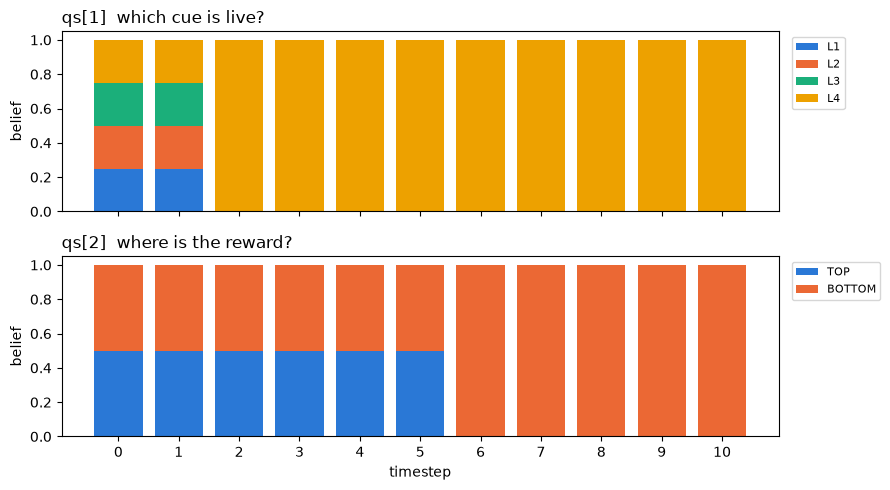

In [12]:
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # categorical, separable under colour vision deficiency

panels = [(1, env.cue2_names, "qs[1]  which cue is live?"),
          (2, env.reward_condition_names, "qs[2]  where is the reward?")]

fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
for ax, (factor, names, title) in zip(axes, panels):
    q = np.asarray(info["qs"][factor][0])  # (T + 1, num_states)
    bottom = np.zeros(T + 1)
    for i, name in enumerate(names):
        ax.bar(np.arange(T + 1), q[:, i], bottom=bottom, color=CAT[i], label=name)
        bottom = bottom + q[:, i]
    ax.set_title(title, loc="left")
    ax.set_ylabel("belief")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8)

axes[-1].set_xlabel("timestep")
axes[-1].set_xticks(np.arange(T + 1))
fig.tight_layout()
plt.show()

The belief about the active cue, `qs[1]`, collapses onto L4 at $t=2$, when the agent stands on CUE1. The belief about the reward condition, `qs[2]`, collapses onto R2 at $t=6$, when the agent stands on L4. Between these points neither belief changes, since every other square returns `Null` on both cue modalities. Together, these observations are consistent with the agent visiting each cue for the information it carries. In the next section, we ask how far ahead the agent must plan for this behaviour to appear.

## 9. Horizon, Preference Scale and Shaping

Section 4 stated that the planning horizon is the binding constraint in this task, and that the scale of `C` interacts with the epistemic term. Both statements can be tested directly.

The cell below first multiplies `C` by 0.1, 10 and 100 and checks whether the trajectory changes. It then varies `policy_len` from 1 to 4 with the preferences held fixed. For each run, we record whether the agent reached CUE1 and the active cue L4, how many distinct squares it visited, and which reward outcomes it observed.

In [13]:
def episode(C, policy_len, e=env, steps=14, **agent_options):
    D = [e.D[0], D_agent[1], D_agent[2]]
    ag = Agent(A=e.A, B=e.B, C=C, D=D,
               A_dependencies=e.A_dependencies, B_dependencies=e.B_dependencies,
               policy_len=policy_len, action_selection="deterministic", batch_size=1,
               **agent_options)
    _, out = rollout(ag, e, num_timesteps=steps, rng_key=jr.PRNGKey(0))
    locations = [int(out["observation"][0][0, t, 0]) for t in range(steps + 1)]
    rewards = [e.reward_obs_names[int(out["observation"][3][0, t, 0])] for t in range(steps + 1)]
    return locations, list(dict.fromkeys(r for r in rewards if r != "Null"))


reference = episode(C, 4)[0]
for k in (0.1, 10, 100):
    assert episode([k * c for c in C], 4)[0] == reference
print("multiplying C by 0.1, 10 or 100 leaves this trajectory unchanged\n")

for policy_len in (1, 2, 3, 4):
    locations, outcomes = episode(C, policy_len)
    print(f"policy_len={policy_len}  {5 ** policy_len:>5} policies  "
          f"CUE1 {str(i_cue1 in locations):<5}  L4 {str(i_L4 in locations):<5}  "
          f"squares visited {len(set(locations)):>2}  outcomes {outcomes or ['none']}")

multiplying C by 0.1, 10 or 100 leaves this trajectory unchanged

policy_len=1      5 policies  CUE1 False  L4 False  squares visited  1  outcomes ['none']
policy_len=2     25 policies  CUE1 True   L4 False  squares visited  3  outcomes ['none']
policy_len=3    125 policies  CUE1 True   L4 False  squares visited  3  outcomes ['none']
policy_len=4    625 policies  CUE1 True   L4 True   squares visited 11  outcomes ['Cheese']


Multiplying `C` by factors from 0.1 to 100 leaves the trajectory unchanged. This is a property of the layout, and does not hold in general. On every square the agent visits before L4, both reward squares lie at least five steps away, beyond the horizon of four. A reward square first comes within reach on L4, and by then the reward condition is known, so the epistemic value of every policy is zero. The pragmatic and epistemic terms are therefore never in competition, and their relative weight has no effect on the chosen actions.

The horizon, by contrast, determines how much of the chain the agent can complete. With `policy_len=1`, the agent never leaves the starting square. With `policy_len=2` or `3`, it reaches CUE1, two steps away, and then stops. This is because L4 lies four steps beyond CUE1, outside the horizon, so all policies available at CUE1 score alike. Only with `policy_len=4`, which matches the longest gap in the chain, does the agent complete the task, and each link of the chain therefore requires a horizon at least as long as the gap it spans.

The number of policies grows as $5^{\texttt{policy\_len}}$. On a model this small, the wall-clock time grows far more slowly, since policies are scored in parallel. However, the exponential becomes limiting once the state space, the action set and the horizon grow together.

For the scale of `C` to matter, the two terms must compete. In the next cell, the agent starts at (2, 5), one step from both R1 and R2. Stepping onto either reward square is then informative, since the outcome reveals the reward condition, but it also risks the shock. We run this configuration with `C` multiplied by 0.1, 1 and 10.

In [14]:
env_between = CueChainingEnv(
    grid_shape=(5, 7),
    start_location=(2, 5),
    cue1_location=(2, 0),
    cue2_locations=((0, 2), (1, 3), (3, 3), (4, 2)),
    reward_locations=((1, 5), (3, 5)),
    cue2_state=3,
    reward_condition=1,
)

for k in (0.1, 1, 10):
    locations, outcomes = episode([k * c for c in C], 4, e=env_between, steps=20)
    squares = [env_between.index_to_coords(i) for i in locations]
    t_reward = next(t for t, xy in enumerate(squares) if xy in env_between.reward_locations)
    print(f"C x {k:<4}  L4 {str(i_L4 in locations):<5}  "
          f"first on a reward square at t={t_reward:>2}  outcomes {outcomes}")

C x 0.1   L4 True   first on a reward square at t= 1  outcomes ['Shock', 'Cheese']
C x 1     L4 True   first on a reward square at t=13  outcomes ['Cheese']
C x 10    L4 True   first on a reward square at t=13  outcomes ['Cheese']


With `C` multiplied by 1 or 10, the agent avoids the gamble. It searches the candidate cue squares L2, L1 and L4 in turn, learns the reward condition on L4, and reaches the cheese at $t=13$ without a shock. With `C` multiplied by 0.1, it first steps onto R1 at $t=1$ and receives the shock, which reveals that the cheese is at R2. Roughly, a single visit to R1 carries an expected utility of $\tfrac{1}{2}(3k) + \tfrac{1}{2}(-6k) = -1.5k$ and resolves $\ln 2 \approx 0.69$ nats about the reward condition. With $k=0.1$ the information outweighs the expected cost, and with $k \geq 1$ it does not. Scaling `C` therefore changes behaviour whenever policies trade pragmatic against epistemic value, and its lack of effect in the main task reflects the layout.

Interestingly, after the shock the weakly motivated agent does not walk straight to R2, two steps away. It follows the same search through L2, L1 and L4, resolving which cue is active although this no longer matters for the reward, and reaches the cheese at the same timestep. This appears to be because the epistemic term values uncertainty about every hidden state factor, whether or not it bears on the reward, and with weak preferences the remaining uncertainty about the cue outweighs the cheese. Together, these runs suggest that the trade-off between exploration and exploitation remains under active inference, with its balance set by the scale of `C` relative to the epistemic term.

A related question is what the epistemic term contributes on its own. The next cell removes it by setting `use_states_info_gain=False`, so that each policy is scored by expected utility alone, and runs this reward-only agent from the original start with the same horizon of four.

In [15]:
for use_states_info_gain in (True, False):
    locations, outcomes = episode(C, 4, use_states_info_gain=use_states_info_gain)
    print(f"use_states_info_gain={str(use_states_info_gain):<5}  "
          f"CUE1 {str(i_cue1 in locations):<5}  L4 {str(i_L4 in locations):<5}  "
          f"squares visited {len(set(locations)):>2}  outcomes {outcomes or ['none']}")

use_states_info_gain=True   CUE1 True   L4 True   squares visited 11  outcomes ['Cheese']
use_states_info_gain=False  CUE1 False  L4 False  squares visited  1  outcomes ['none']


Without the epistemic term, the agent never leaves the starting square, since no reward lies within four steps of it. It should be noted that this does not show that reward maximisation cannot solve the task. In `pymdp`, a policy is a fixed sequence of actions, scored before any of its observations arrive, so a reward-only agent of this kind cannot use what a cue would reveal at any horizon. A planner over belief states, which conditions later actions on earlier observations, would value the cues through their contribution to future reward, as in the Bellman equation for a POMDP (Sec. 4). However, it would need to plan around ten steps ahead, from the start through CUE1 and L4 to R2, a far larger search than the 625 policies used here. Model-free reinforcement learning can likewise learn the value of the cues, but across many episodes. We make no claim that active inference outperforms these methods, only that the value of the cues arises differently, since the epistemic term values each cue directly and a horizon spanning the longest gap between cues is sufficient.

A cheaper alternative to a longer horizon is to shape `C` over the location modality, with a preference that increases as the distance to the nearest reward square decreases. Every step towards a reward square is then preferred, and a horizon of one suffices. The next cell compares this shaped agent with the epistemic agent, first with the reward at R1 and then at R2.

In [16]:
def env_with_reward_at(reward_condition):
    return CueChainingEnv(
        grid_shape=(5, 7),
        start_location=(0, 0),
        cue1_location=(2, 0),
        cue2_locations=((0, 2), (1, 3), (3, 3), (4, 2)),
        reward_locations=((1, 5), (3, 5)),
        cue2_state=3,
        reward_condition=reward_condition,
    )


coordinates = np.array([env.index_to_coords(i) for i in range(env.A[0].shape[0])])
targets = np.array(env.reward_locations)
distance = np.abs(coordinates[:, None, :] - targets[None, :, :]).sum(-1).min(-1)

C_shaped = list(C)
C_shaped[0] = jnp.asarray(-distance, dtype=jnp.float32)  # a potential pulling towards either reward

for reward_condition in (0, 1):
    e = env_with_reward_at(reward_condition)
    for label, preferences, policy_len in [("epistemic", C, 4),
                                           ("shaped   ", C_shaped, 1),
                                           ("shaped   ", C_shaped, 2)]:
        locations, outcomes = episode(preferences, policy_len, e=e)
        cues = sum(i in locations for i in (i_cue1, i_L4))
        print(f"reward at {e.reward_locations[reward_condition]}  {label}  policy_len={policy_len}  "
              f"cues visited {cues}  outcomes {outcomes or ['none']}")
    print()

reward at (1, 5)  epistemic  policy_len=4  cues visited 2  outcomes ['Cheese']
reward at (1, 5)  shaped     policy_len=1  cues visited 0  outcomes ['Cheese']
reward at (1, 5)  shaped     policy_len=2  cues visited 0  outcomes ['Cheese']

reward at (3, 5)  epistemic  policy_len=4  cues visited 2  outcomes ['Cheese']
reward at (3, 5)  shaped     policy_len=1  cues visited 0  outcomes ['Shock']
reward at (3, 5)  shaped     policy_len=2  cues visited 0  outcomes ['Shock', 'Cheese']



With the reward at either location, the epistemic agent visits both cues and collects the cheese, taking a different route in each case because the cue indicates which route to take.

The shaped agent visits neither cue and walks to R1 in both cases, since the shaped preference cannot distinguish the two reward squares. It is therefore correct half of the time by construction. With `policy_len=1`, it receives a shock when the reward is at R2 and does not recover. It steps off R1 to the square above it and stays there, because the cheese is now three steps away and its horizon is one. With `policy_len=2`, it does recover, inferring the reward condition from the shock itself and walking to R2.

This last case clarifies what shaping provides. The agent still needs the information, and shaping changes only how it is acquired, replacing a visit to a cue with an aversive outcome. A shaped preference that routed the agent through the cues first would need to encode the solution in advance, which the task was designed to prevent. In the next section, we remove part of the model itself and ask whether the agent can learn it.

## 10. Learning the Likelihood

So far, the agent has been given the true `A` and `B`, leaving nothing to learn. In this section, we remove part of that knowledge.

Learning is enabled by supplying Dirichlet priors `pA` and `pB` and setting `learn_A` or `learn_B`. `rollout` then calls `agent.infer_parameters` at every step when `learning_mode="online"`, or once at the end when it is `"offline"`, and `info["pA"]` and `info["pB"]` record the concentration parameters over time. Here, the concentration parameters act as counts of how often each observation has been seen in each state.

Below, we flatten the cue2 likelihood, so that the agent believes that modality to be uninformative noise, and give it a flat Dirichlet prior to update. This creates a circular difficulty. Under state information gain alone, a modality believed to be noise promises nothing about the hidden states, so the agent has no reason to visit the cue, and it cannot learn about observations it never samples.

Setting `use_param_info_gain=True` adds a third term to the expected free energy, often called 'novelty', which scores observations by how much they are expected to sharpen the model parameters. We therefore expect the agent to visit L4 only when this term is included.

In [17]:
A_naive = list(env.A)
A_naive[2] = jnp.ones_like(env.A[2]) / env.A[2].shape[0]  # cue2 taken to be noise

pA = [a * 1e4 for a in env.A]     # counts too high to move
pA[2] = jnp.ones_like(env.A[2])   # flat Dirichlet over the cue2 likelihood

learning_steps = 20


def learn(use_param_info_gain):
    ag = Agent(A=A_naive, B=env.B, C=C, D=D_agent, pA=pA, learn_A=True,
               use_param_info_gain=use_param_info_gain,
               A_dependencies=env.A_dependencies, B_dependencies=env.B_dependencies,
               policy_len=4, action_selection="deterministic", batch_size=1)
    _, out = rollout(ag, env, num_timesteps=learning_steps, rng_key=jr.PRNGKey(0))
    locations = [int(out["observation"][0][0, t, 0]) for t in range(learning_steps + 1)]
    counts = np.asarray(out["pA"][2][0, -1, :, i_L4, 3, 1])
    return locations.count(i_L4), counts


print("counts over", env.cue2_obs_names, "at L4, where the truth is", env.cue2_obs_names[2])
for novelty in (False, True):
    visits, counts = learn(novelty)
    print(f"use_param_info_gain={str(novelty):<5}  L4 visits {visits}  counts {counts}")

counts over ('Null', 'reward_on_top', 'reward_on_bottom') at L4, where the truth is reward_on_bottom
use_param_info_gain=False  L4 visits 0  counts [1. 1. 1.]
use_param_info_gain=True   L4 visits 2  counts [1. 1. 2.]


Without novelty, the agent never visits L4 and the counts remain at their prior values. With novelty, it visits L4 twice and the count for `reward_on_bottom` rises from 1 to 2. Interestingly, two visits add only one count. This is because the agent treats cue2 as noise, so standing on L4 tells it nothing about the reward condition, and each update is split equally between the two conditions. The agent therefore also records `reward_on_bottom` under the condition in which the reward is at R1, which is incorrect. Separating the two conditions would require many episodes in which the reward condition becomes known by other means, and we leave such learning curves for future work. In the final section, we animate the episode from Sec. 8.

## 11. Animation

The final cell animates the episode from Sec. 8 using `FuncAnimation` and `PillowWriter`, which need no dependency beyond matplotlib. The mouse, cheese and shock images are the sprites that `pymdp` ships under `pymdp/envs/assets/`.

The left panel shows the environment, including the active cue and the positions of the cheese and the shock, taken from `info["env_state"]`. None of this is observed by the agent. The right panels show the agent's beliefs about the same two quantities, so the figure contrasts what is true with what the agent believes at each step. The animation is saved to `cue-chaining.gif` for use in slides.

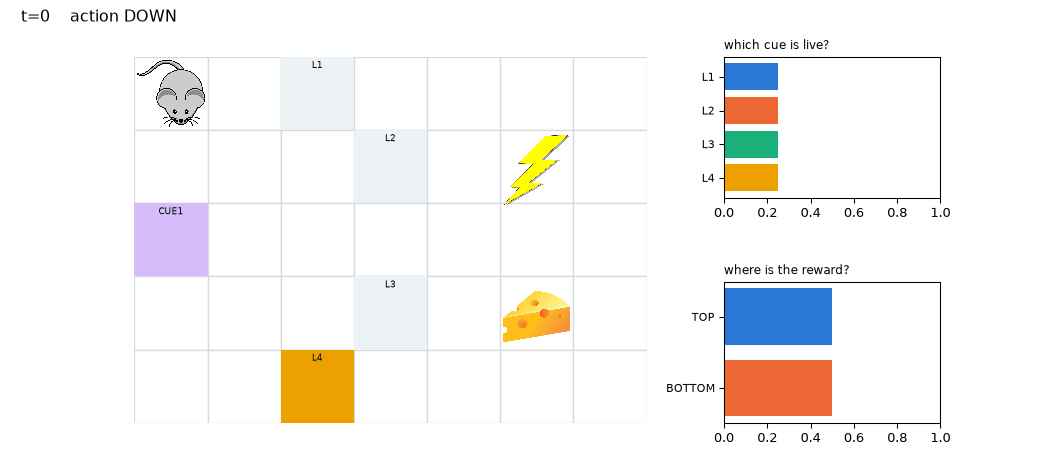

In [18]:
import os
from matplotlib import animation
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
import pymdp.envs

ASSETS = os.path.join(os.path.dirname(pymdp.envs.__file__), "assets")
mouse = plt.imread(os.path.join(ASSETS, "mouse.png"))
cheese = plt.imread(os.path.join(ASSETS, "cheese.png"))
shock = plt.imread(os.path.join(ASSETS, "shock.png"))

rows, cols = env.grid_shape
live_cue = int(info["env_state"][1][0, 0])
reward_condition = int(info["env_state"][2][0, 0])
path = [env.index_to_coords(observed(0, t)) for t in timesteps]


def sprite(ax, image, position, zoom):
    ax.add_artist(AnnotationBbox(OffsetImage(image, zoom=zoom), position, frameon=False))


def draw_maze(ax, t):
    ax.clear()
    for r in range(rows):
        for c in range(cols):
            ax.add_patch(plt.Rectangle((c, r), 1, 1, facecolor="white", edgecolor="0.85"))

    r, c = env.cue1_location
    ax.add_patch(plt.Rectangle((c, r), 1, 1, facecolor="#d6bcfa"))
    ax.text(c + 0.5, r + 0.15, "CUE1", ha="center", fontsize=7)

    for i, (r, c) in enumerate(env.cue2_locations):
        ax.add_patch(plt.Rectangle((c, r), 1, 1, facecolor=CAT[3] if i == live_cue else "#edf2f7"))
        ax.text(c + 0.5, r + 0.15, env.cue2_names[i], ha="center", fontsize=7)

    for i, (r, c) in enumerate(env.reward_locations):
        won = i == reward_condition
        sprite(ax, cheese if won else shock, (c + 0.5, r + 0.55), 0.017 if won else 0.09)

    xs = [c + 0.5 for _, c in path[:t + 1]]
    ys = [r + 0.5 for r, _ in path[:t + 1]]
    ax.plot(xs, ys, color=CAT[0], lw=2, alpha=0.6)
    sprite(ax, mouse, (xs[-1], ys[-1]), 0.026)

    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)
    ax.set_aspect("equal")
    ax.axis("off")


def draw_beliefs(ax, factor, names, title, t):
    ax.clear()
    ax.barh(np.arange(len(names)), np.asarray(info["qs"][factor][0, t]), color=CAT[:len(names)])
    ax.set_yticks(np.arange(len(names)))
    ax.set_yticklabels(names, fontsize=8)
    ax.set_xlim(0, 1)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=9, loc="left")


def draw(t):
    draw_maze(ax_maze, t)
    draw_beliefs(ax_cue, 1, env.cue2_names, "which cue is live?", t)
    draw_beliefs(ax_reward, 2, env.reward_condition_names, "where is the reward?", t)
    row = trajectory.loc[t]
    seen = [v for v in (row.cue1, row.cue2, row.reward) if v != "Null"]
    fig.suptitle(f"t={t}    action {row.action}" + (f"    observed {', '.join(seen)}" if seen else ""),
                 x=0.02, ha="left", fontsize=12)


fig = plt.figure(figsize=(11, 5))
grid = fig.add_gridspec(2, 2, width_ratios=[2.4, 1], hspace=0.6)
ax_maze = fig.add_subplot(grid[:, 0])
ax_cue = fig.add_subplot(grid[0, 1])
ax_reward = fig.add_subplot(grid[1, 1])

anim = animation.FuncAnimation(fig, draw, frames=list(timesteps), interval=700)
anim.save("cue-chaining.gif", writer=animation.PillowWriter(fps=1.4), dpi=95)
plt.close(fig)

Image(filename="cue-chaining.gif")

## 12. Summary

In this notebook, we built a generative model for the cue chaining task and followed an active inference agent through it. The agent visited both cues before approaching the reward, and its beliefs about the active cue and the reward location changed only on the cue squares (Sec. 8). This behaviour required a planning horizon at least as long as the longest gap in the chain, and the number of policies grows exponentially with that horizon (Sec. 9). Without the epistemic term, the same agent did not move, and the scale of the preferences changed behaviour only where pragmatic and epistemic value were in competition, so the balance between exploration and exploitation is set in part by the scale of `C`. Shaping the preferences reduced the required horizon, but when the reward was at R2 it replaced the visit to a cue with exposure to the shock. When part of the likelihood was unknown, the agent visited the cue only when parameter information gain was included in the expected free energy (Sec. 10).

However, the task is small, fully discrete and solved within a single episode. A promising direction is to extend these ideas to longer horizons and learned models, where the cost of enumerating policies becomes the main limitation.